# Lab 4: Regression Analysis with Regularization Techniques

**Name:** Abhilash Reddy Marthala  
**Course:** MSCS 634 — Advanced Big Data and Data Mining   
**Assignment:** Lab 4

## Objective

This lab compares simple linear regression, multiple regression,
polynomial regression, Ridge regression, and Lasso regression using
the scikit-learn Diabetes dataset.

Models are evaluated using MAE, MSE, RMSE, and R². The analysis also
examines how polynomial degree and regularization strength affect
model complexity and generalization.

In [1]:
%pip install numpy pandas matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

RANDOM_STATE = 42

## 1. Data Preparation

The Diabetes dataset contains 442 observations and 10 input features.
The target is a quantitative measure of disease progression one year
after baseline.

Raw feature values are loaded so that any scaling can be learned
only from the training data.

In [3]:
diabetes = load_diabetes(as_frame=True, scaled=False)

X = diabetes.data.copy()
y = diabetes.target.copy()

df = X.copy()
df["target"] = y

print("Dataset shape:", df.shape)
print("Feature names:", X.columns.tolist())

display(df.head())
display(df.describe())

print("\nDataset information:")
df.info()

Dataset shape: (442, 11)
Feature names: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000,442.000000
mean,48.518100,1.468326,26.375792,94.647014,189.140271,115.439140,49.788462,4.070249,4.641411,91.260181,152.133484
std,13.109028,0.499561,4.418122,13.831283,34.608052,30.413081,12.934202,1.290450,0.522391,11.496335,77.093005
min,19.000000,1.000000,18.000000,62.000000,97.000000,41.600000,22.000000,2.000000,3.258100,58.000000,25.000000
25%,38.250000,1.000000,23.200000,84.000000,164.250000,96.050000,40.250000,3.000000,4.276700,83.250000,87.000000
50%,50.000000,1.000000,25.700000,93.000000,186.000000,113.000000,48.000000,4.000000,4.620050,91.000000,140.500000
75%,59.000000,2.000000,29.275000,105.000000,209.750000,134.500000,57.750000,5.000000,4.997200,98.000000,211.500000
max,79.000000,2.000000,42.200000,133.000000,301.000000,242.400000,99.000000,9.090000,6.107000,124.000000,346.000000



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [4]:
print("Missing values:")
display(df.isna().sum())

print("Duplicate rows:", df.duplicated().sum())
print("Missing target values:", y.isna().sum())

Missing values:


age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Duplicate rows: 0
Missing target values: 0


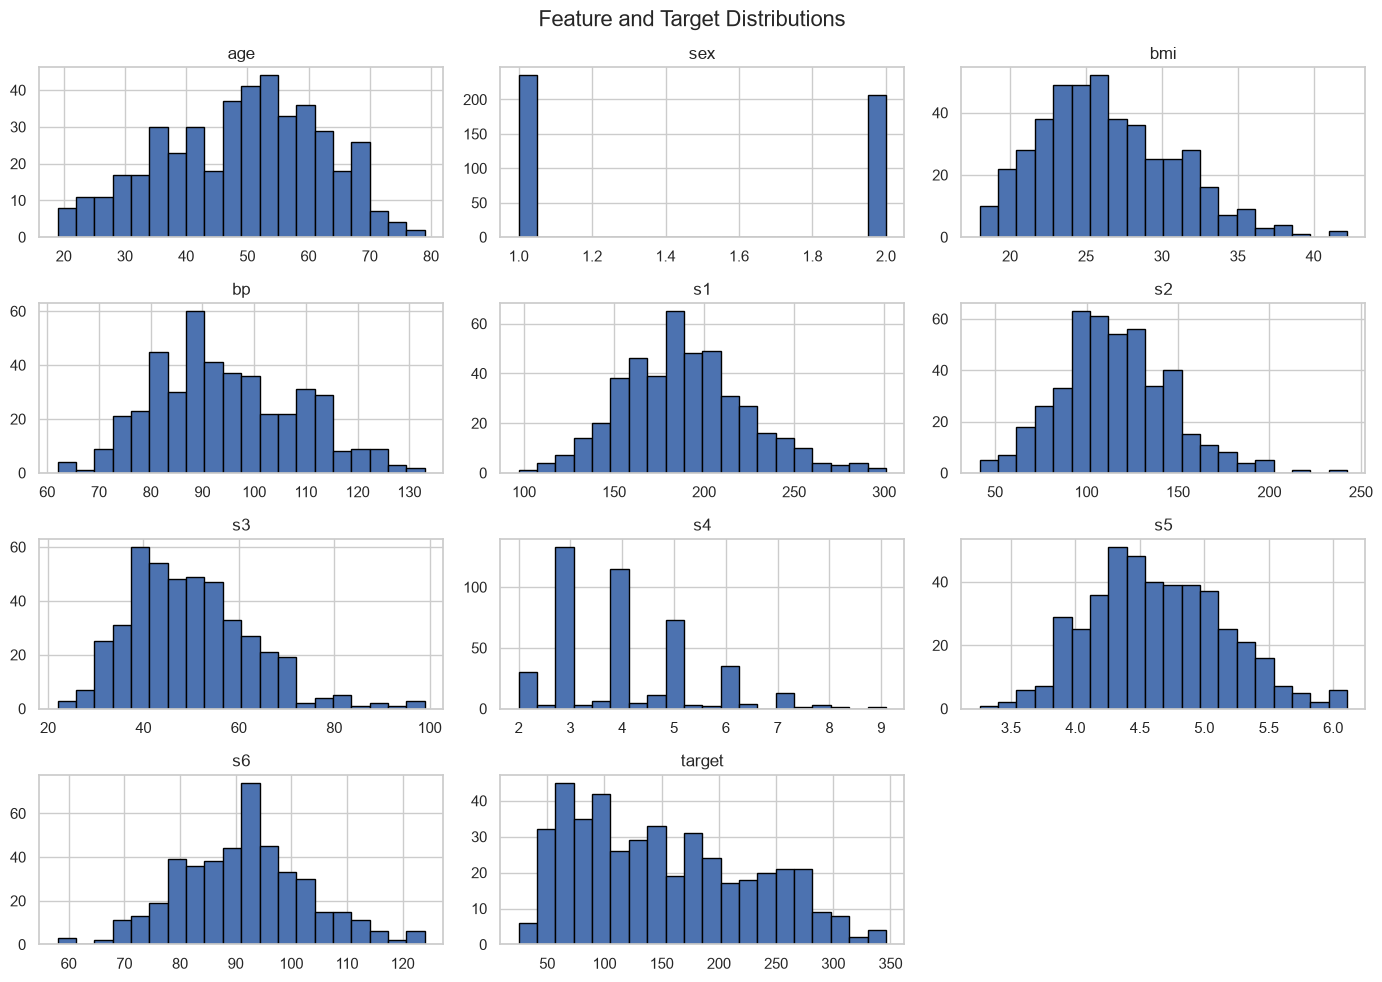

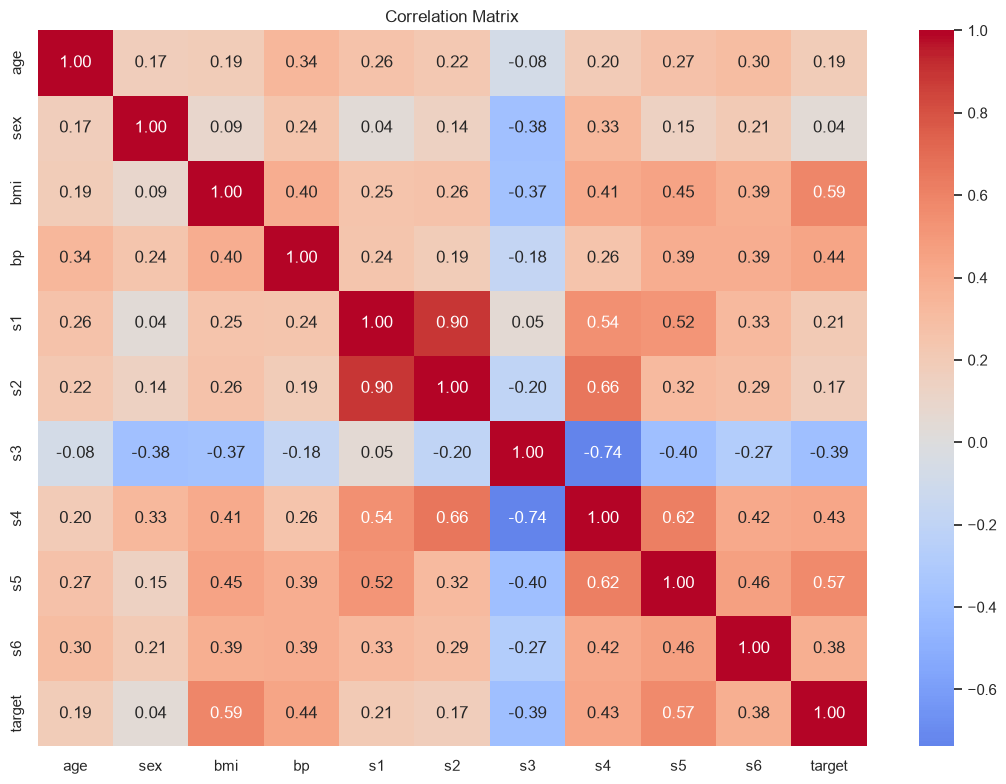

In [5]:
df.hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.suptitle("Feature and Target Distributions", fontsize=16)
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 8))
sns.heatmap(
    df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

### Data Preparation Observations

- Missing-value and duplicate checks were performed before modeling.
- Feature distributions were inspected using histograms.
- Correlations describe associations and do not establish causation.
- BMI is used as the predefined predictor for simple regression.
- All ten features are used for multiple regression and regularization.
- Exploratory plots provide context; model hyperparameters are selected
  using cross-validation within the training set.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

# Used to select hyperparameters using training data only.
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

results = []
predictions = {}

Training observations: 353
Testing observations: 89


In [7]:
def evaluate_model(name, model, X_train_used, X_test_used):
    train_pred = model.predict(X_train_used)
    test_pred = model.predict(X_test_used)

    row = {
        "Model": name,
        "MAE": mean_absolute_error(y_test, test_pred),
        "MSE": mean_squared_error(y_test, test_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "R²": r2_score(y_test, test_pred),
        "Train RMSE": np.sqrt(
            mean_squared_error(y_train, train_pred)
        )
    }

    # Allows a cell to be rerun without adding duplicate result rows.
    results[:] = [r for r in results if r["Model"] != name]
    results.append(row)
    predictions[name] = test_pred

    return pd.DataFrame([row]).round(4)


def plot_actual_vs_predicted(actual, predicted, title):
    low = min(actual.min(), predicted.min())
    high = max(actual.max(), predicted.max())

    plt.figure(figsize=(6, 5))
    plt.scatter(actual, predicted, alpha=0.7)
    plt.plot([low, high], [low, high], "r--",
             label="Perfect predictions")
    plt.xlabel("Actual Disease Progression")
    plt.ylabel("Predicted Disease Progression")
    plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.show()

## 2. Simple Linear Regression

This model uses BMI as its only independent variable to predict
disease progression. It provides a baseline for the more complex models.

In [8]:
X_train_bmi = X_train[["bmi"]]
X_test_bmi = X_test[["bmi"]]

simple_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

simple_model.fit(X_train_bmi, y_train)

display(evaluate_model(
    "Simple Linear Regression",
    simple_model,
    X_train_bmi,
    X_test_bmi
))

,Model,MAE,MSE,RMSE,R²,Train RMSE
0,Simple Linear Regression,52.26,4061.8259,63.7325,0.2334,62.0815


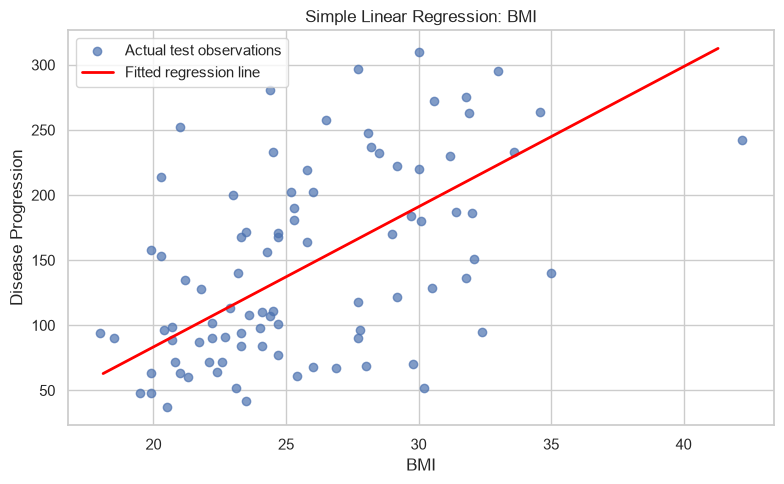

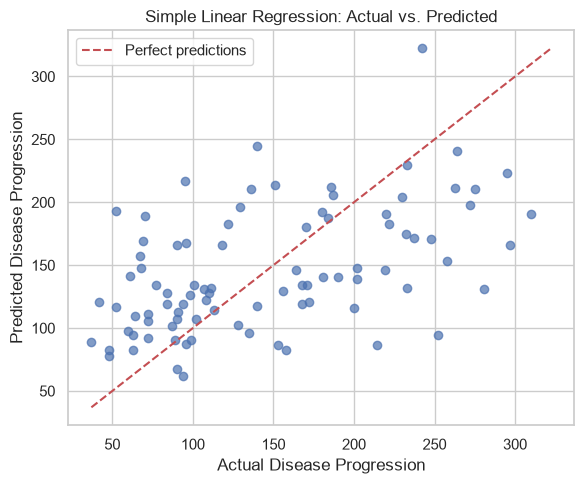

In [9]:
bmi_grid = pd.DataFrame({
    "bmi": np.linspace(
        X_train["bmi"].min(),
        X_train["bmi"].max(),
        200
    )
})

plt.figure(figsize=(8, 5))
plt.scatter(
    X_test["bmi"], y_test,
    alpha=0.7, label="Actual test observations"
)
plt.plot(
    bmi_grid["bmi"],
    simple_model.predict(bmi_grid),
    color="red",
    linewidth=2,
    label="Fitted regression line"
)
plt.xlabel("BMI")
plt.ylabel("Disease Progression")
plt.title("Simple Linear Regression: BMI")
plt.legend()
plt.tight_layout()
plt.show()

plot_actual_vs_predicted(
    y_test,
    predictions["Simple Linear Regression"],
    "Simple Linear Regression: Actual vs. Predicted"
)

## 3. Multiple Regression

Multiple regression uses all ten input features. Comparing this model
with the BMI-only model shows whether additional predictors improve
prediction on the same test observations.

,Model,MAE,MSE,RMSE,R²,Train RMSE
0,Multiple Regression,42.7941,2900.1936,53.8534,0.4526,53.5588


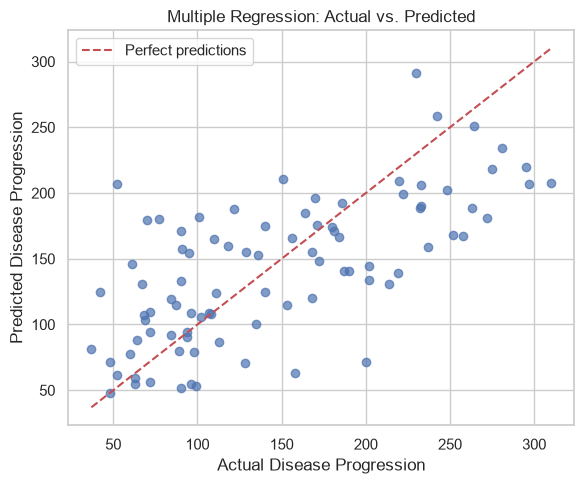

In [10]:
multiple_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

multiple_model.fit(X_train, y_train)

display(evaluate_model(
    "Multiple Regression",
    multiple_model,
    X_train,
    X_test
))

plot_actual_vs_predicted(
    y_test,
    predictions["Multiple Regression"],
    "Multiple Regression: Actual vs. Predicted"
)

## 4. Polynomial Regression

Polynomial regression models nonlinear relationships by adding powers
of BMI. Degrees 1, 2, 3, 5, and 10 are examined.

Training RMSE and cross-validation RMSE are compared to investigate
model complexity. The degree is selected using training-set
cross-validation, not test-set performance.

A widening gap between training and validation error suggests
overfitting. High error on both can suggest underfitting.

In [11]:
polynomial_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("poly", PolynomialFeatures(include_bias=False)),
    ("model", LinearRegression())
])

polynomial_search = GridSearchCV(
    estimator=polynomial_pipeline,
    param_grid={"poly__degree": [1, 2, 3, 5, 10]},
    scoring="neg_mean_squared_error",
    cv=cv,
    return_train_score=True
)

polynomial_search.fit(X_train_bmi, y_train)

poly_cv = pd.DataFrame(polynomial_search.cv_results_)

degree_results = pd.DataFrame({
    "Degree": poly_cv["param_poly__degree"].astype(int),
    "Training RMSE": np.sqrt(-poly_cv["mean_train_score"]),
    "CV RMSE": np.sqrt(-poly_cv["mean_test_score"])
}).sort_values("Degree")

display(degree_results.round(4))

best_degree = polynomial_search.best_params_["poly__degree"]
print("Best degree selected by cross-validation:", best_degree)

,Degree,Training RMSE,CV RMSE
0,1,62.0343,62.5232
1,2,61.9669,62.7458
2,3,61.9435,62.8780
3,5,61.7166,62.9876
4,10,60.7870,272.6599


Best degree selected by cross-validation: 1


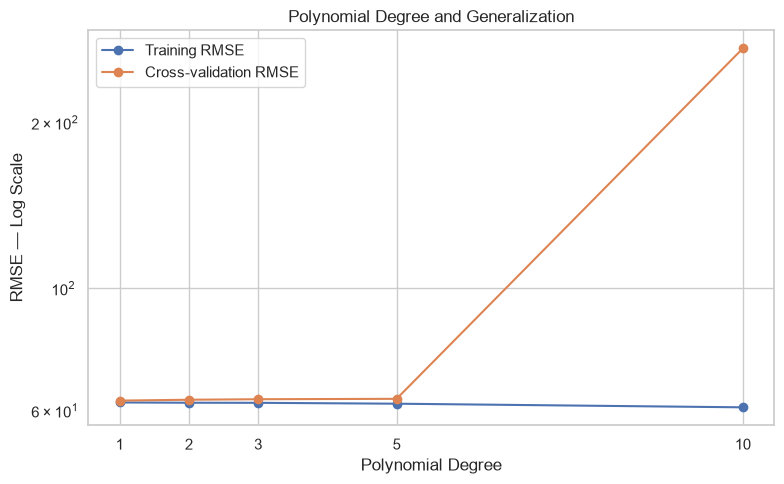

,Model,MAE,MSE,RMSE,R²,Train RMSE
0,Polynomial Regression (degree 1),52.26,4061.8259,63.7325,0.2334,62.0815


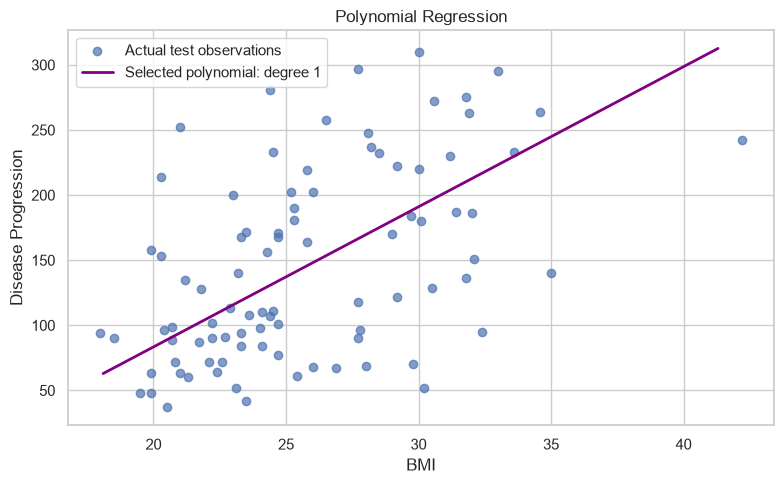

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(
    degree_results["Degree"],
    degree_results["Training RMSE"],
    marker="o",
    label="Training RMSE"
)
plt.plot(
    degree_results["Degree"],
    degree_results["CV RMSE"],
    marker="o",
    label="Cross-validation RMSE"
)
plt.yscale("log")
plt.xlabel("Polynomial Degree")
plt.ylabel("RMSE — Log Scale")
plt.title("Polynomial Degree and Generalization")
plt.xticks(degree_results["Degree"])
plt.legend()
plt.tight_layout()
plt.show()

poly_name = f"Polynomial Regression (degree {best_degree})"

display(evaluate_model(
    poly_name,
    polynomial_search.best_estimator_,
    X_train_bmi,
    X_test_bmi
))

plt.figure(figsize=(8, 5))
plt.scatter(
    X_test["bmi"], y_test,
    alpha=0.7, label="Actual test observations"
)
plt.plot(
    bmi_grid["bmi"],
    polynomial_search.predict(bmi_grid),
    color="purple",
    linewidth=2,
    label=f"Selected polynomial: degree {best_degree}"
)
plt.xlabel("BMI")
plt.ylabel("Disease Progression")
plt.title("Polynomial Regression")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Ridge and Lasso Regularization

Both models use all ten input features.

- Ridge uses an L2 penalty that shrinks regression coefficients.
- Lasso uses an L1 penalty and can set some coefficients exactly to zero.
- Increasing alpha strengthens regularization.
- Excessive regularization can cause underfitting.

Features are standardized inside each pipeline. Alpha is selected
through five-fold cross-validation on the training set.

In [13]:
alpha_values = np.logspace(-3, 3, 13)

ridge_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

lasso_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", Lasso(max_iter=100000))
])

ridge_search = GridSearchCV(
    ridge_pipeline,
    {"model__alpha": alpha_values},
    scoring="neg_mean_squared_error",
    cv=cv
)

lasso_search = GridSearchCV(
    lasso_pipeline,
    {"model__alpha": alpha_values},
    scoring="neg_mean_squared_error",
    cv=cv
)

ridge_search.fit(X_train, y_train)
lasso_search.fit(X_train, y_train)

print("Selected Ridge alpha:",
      ridge_search.best_params_["model__alpha"])
print("Selected Lasso alpha:",
      lasso_search.best_params_["model__alpha"])

display(evaluate_model(
    "Ridge Regression",
    ridge_search.best_estimator_,
    X_train,
    X_test
))

display(evaluate_model(
    "Lasso Regression",
    lasso_search.best_estimator_,
    X_train,
    X_test
))

Selected Ridge alpha: 1.0
Selected Lasso alpha: 0.1


,Model,MAE,MSE,RMSE,R²,Train RMSE
0,Ridge Regression,42.812,2892.0146,53.7775,0.4541,53.5751


,Model,MAE,MSE,RMSE,R²,Train RMSE
0,Lasso Regression,42.8052,2884.6243,53.7087,0.4555,53.5984


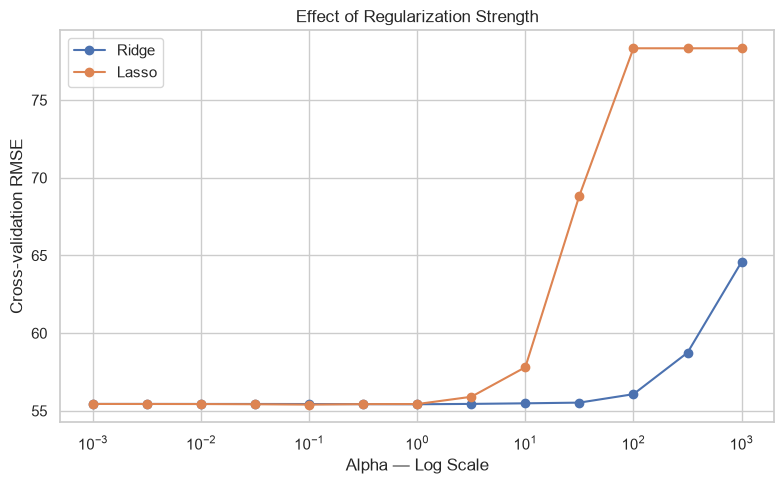

In [14]:
plt.figure(figsize=(8, 5))

for label, search in [
    ("Ridge", ridge_search),
    ("Lasso", lasso_search)
]:
    search_results = pd.DataFrame(search.cv_results_)

    alphas = search_results["param_model__alpha"].astype(float)
    cv_rmse = np.sqrt(-search_results["mean_test_score"])

    plt.plot(alphas, cv_rmse, marker="o", label=label)

plt.xscale("log")
plt.xlabel("Alpha — Log Scale")
plt.ylabel("Cross-validation RMSE")
plt.title("Effect of Regularization Strength")
plt.legend()
plt.tight_layout()
plt.show()

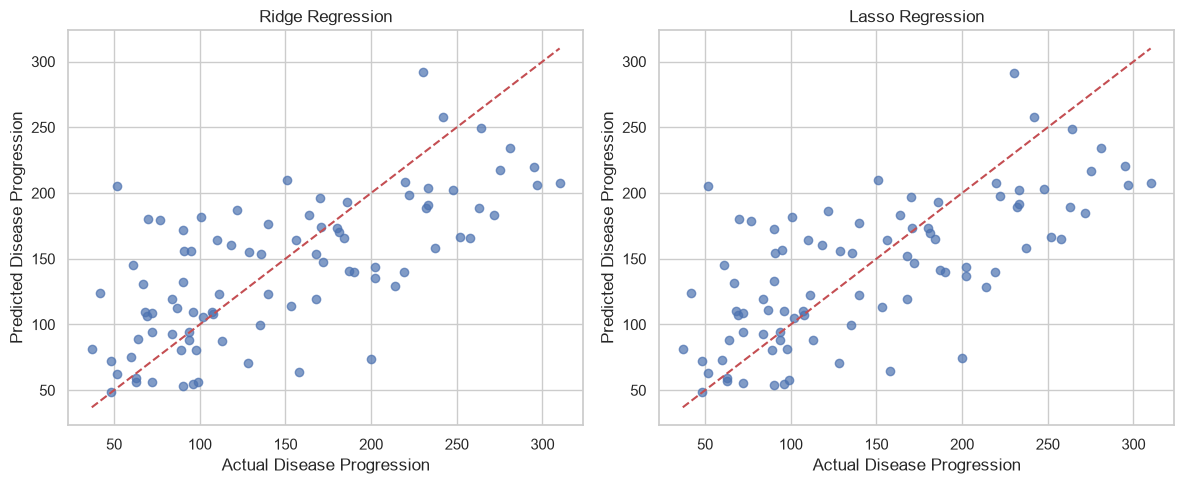

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, name in zip(
    axes, ["Ridge Regression", "Lasso Regression"]
):
    pred = predictions[name]
    low = min(y_test.min(), pred.min())
    high = max(y_test.max(), pred.max())

    ax.scatter(y_test, pred, alpha=0.7)
    ax.plot([low, high], [low, high], "r--")
    ax.set_title(name)
    ax.set_xlabel("Actual Disease Progression")
    ax.set_ylabel("Predicted Disease Progression")

plt.tight_layout()
plt.show()

,Multiple Regression,Ridge,Lasso
Feature,,,
age,1.7538,1.8073,1.7305
sex,-11.5118,-11.4482,-11.3164
bmi,25.6071,25.7327,25.8246
bp,16.8289,16.7343,16.6443
s1,-44.4489,-34.6720,-29.3584
s2,24.6410,17.0531,13.2758
s3,7.6770,3.3699,0.5479
s4,13.1388,11.7643,10.2362
s5,35.1612,31.3784,29.6328


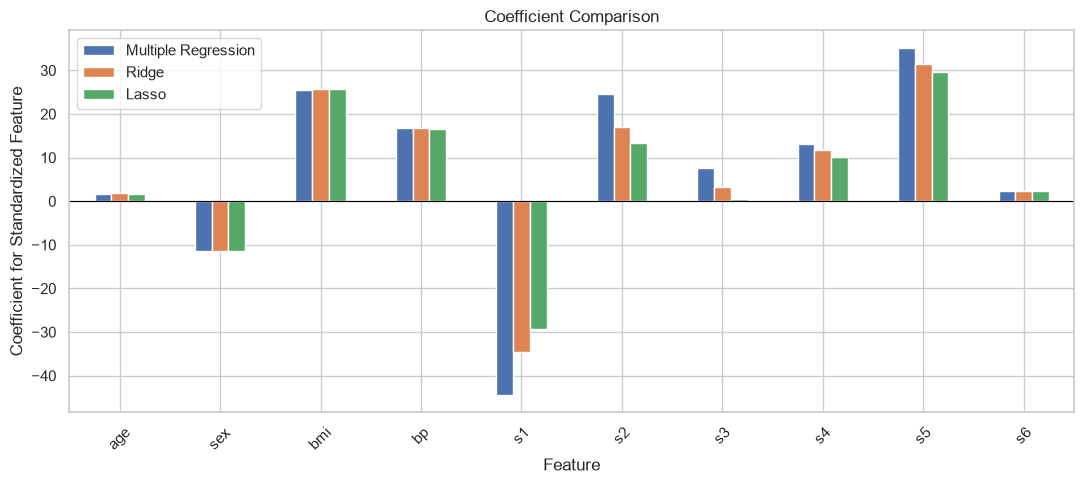

Number of coefficients set to zero by Lasso: 0


In [16]:
coefficient_table = pd.DataFrame({
    "Feature": X.columns,
    "Multiple Regression":
        multiple_model.named_steps["model"].coef_,
    "Ridge":
        ridge_search.best_estimator_.named_steps["model"].coef_,
    "Lasso":
        lasso_search.best_estimator_.named_steps["model"].coef_
}).set_index("Feature")

display(coefficient_table.round(4))

coefficient_table.plot(kind="bar", figsize=(11, 5))
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Coefficient for Standardized Feature")
plt.title("Coefficient Comparison")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

lasso_coefficients = (
    lasso_search.best_estimator_.named_steps["model"].coef_
)

print(
    "Number of coefficients set to zero by Lasso:",
    np.sum(lasso_coefficients == 0)
)

## 6. Model Comparison and Analysis

All models are evaluated using the same test observations.

Simple and polynomial regression use BMI only. Multiple regression,
Ridge, and Lasso use all ten features. Differences therefore reflect
both modeling choices and available predictors.

The test-set results provide a final descriptive comparison.
Hyperparameters were selected using training-set cross-validation.

,MAE,MSE,RMSE,R²,Train RMSE
Model,,,,,
Lasso Regression,42.8052,2884.6243,53.7087,0.4555,53.5984
Ridge Regression,42.8120,2892.0146,53.7775,0.4541,53.5751
Multiple Regression,42.7941,2900.1936,53.8534,0.4526,53.5588
Simple Linear Regression,52.2600,4061.8259,63.7325,0.2334,62.0815
Polynomial Regression (degree 1),52.2600,4061.8259,63.7325,0.2334,62.0815


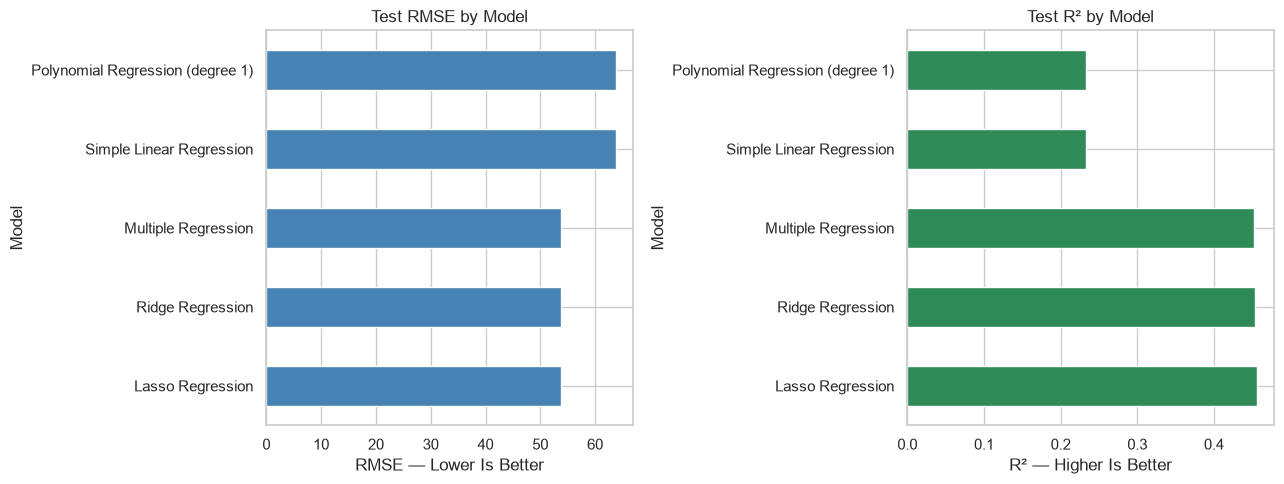

Lowest test RMSE: Lasso Regression
RMSE: 53.7087
R²: 0.4555


In [17]:
comparison_df = (
    pd.DataFrame(results)
    .set_index("Model")
    .sort_values("RMSE")
)

display(comparison_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

comparison_df["RMSE"].plot(
    kind="barh", ax=axes[0], color="steelblue"
)
axes[0].set_title("Test RMSE by Model")
axes[0].set_xlabel("RMSE — Lower Is Better")

comparison_df["R²"].plot(
    kind="barh", ax=axes[1], color="seagreen"
)
axes[1].set_title("Test R² by Model")
axes[1].set_xlabel("R² — Higher Is Better")

plt.tight_layout()
plt.show()

lowest_rmse_model = comparison_df.index[0]

print("Lowest test RMSE:", lowest_rmse_model)
print("RMSE:", round(comparison_df.iloc[0]["RMSE"], 4))
print("R²:", round(comparison_df.iloc[0]["R²"], 4))

### Findings and Discussion

1. **Simple linear regression:**  
   The BMI-only model achieved a test RMSE of [value] and R² of [value].
   This establishes a baseline using a single predictor.

2. **Multiple regression:**  
   Using all ten features produced a test RMSE of [value].
   Compared with simple regression, performance [improved/did not improve].

3. **Polynomial regression:**  
   Cross-validation selected degree [value].
   As degree increased, training error [describe the pattern], while
   cross-validation error [describe the pattern].
   This provides [evidence/no clear evidence] of overfitting at higher degrees.

4. **Ridge regression:**  
   The selected alpha was [value], and test RMSE was [value].
   Compared with unregularized multiple regression, Ridge
   [improved/did not improve] test performance.

5. **Lasso regression:**  
   The selected alpha was [value], and test RMSE was [value].
   Lasso set [number] coefficients to zero.

6. **Overall comparison:**  
   [Model name] had the lowest test RMSE in this experiment.
   Regularization [did/did not] improve the observed test performance.
   It is not guaranteed to improve every dataset or train/test split.

7. **Dataset insights and limitations:**  
   [Describe one or two patterns visible in the correlation matrix.]
   The dataset is relatively small, so results can vary with the split.
   Associations and model coefficients should not be interpreted as
   causal effects or clinical recommendations.